# Estimating Straylight with ROSALIA 

## What is this? 

The purpose of this notebook is to demonstrate the use of ROSALIA. First we will generate a custom ROSALIA exposure object, and then use the `rosalia.core.exposure.straylight()` method to estimate the expected stray-light background from out-of-field sources. The code will generate a series of summary plots (png images) and a background image stored as a FITS format. 

The tutorial is divided on three examples: 

    - Estimating stray-light on a mock observation generated by ROSALIA
    - Estimating stray-light on a real observation file

## How to start

To run this notebook, please activate the "rosalia" kernel at the top right of your window.

## Imports

- *rosalia* for Roman/WFI stray-light analysis
- *astropy.time* to determine the start of the observation. 
- *asdf* for accessing the ASDF Roman mock observations
- *s3fs* for accessing the S3 cloud files in the Nexus
- *os* for Python path processing 

In [1]:
import rosalia as rs
from astropy.time import Time

### 1 - Estimating stray-light on a mock observation generated by ROSALIA

> Synthetic Roman_wfi_exposure
2026-10-20T16:16:58.597073 > Fetching source catalog
find_mosaic_wcs: Loading existing catalog! Remove Pleiades_Roman_RA_056.658_DEC_024.178_MJD_61314.00000_PA_000.00_source_catalog.csv if this is a mistake.
2026-10-20T16:16:59.129077 > Done.


18it [00:03,  5.40it/s]

2026-10-20T16:17:02.474695 > Starting Stray-light scan: 



100%|██████████| 18/18 [01:01<00:00,  3.44s/it]


2026-10-20T16:18:05.478540 > Done : 0:01:03.003870 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-10-20T16:18:06.458230 > Done : 
TODO: Add option to provide optimal_wcs - So multiple filters can share target grid
Assuming user-input resolution is on arcsecs
DATA / WCS mode
TODO: Add option to provide optimal_wcs - So multiple filters can share target grid
Assuming user-input resolution is on arcsecs
DATA / WCS mode
2026-10-20T16:18:13.940885 > Summary plots... 
Plot: Stray-light surface brightness magnitude.
DEMO WARNING: make_stray_plot is Assuming F129.
25
35


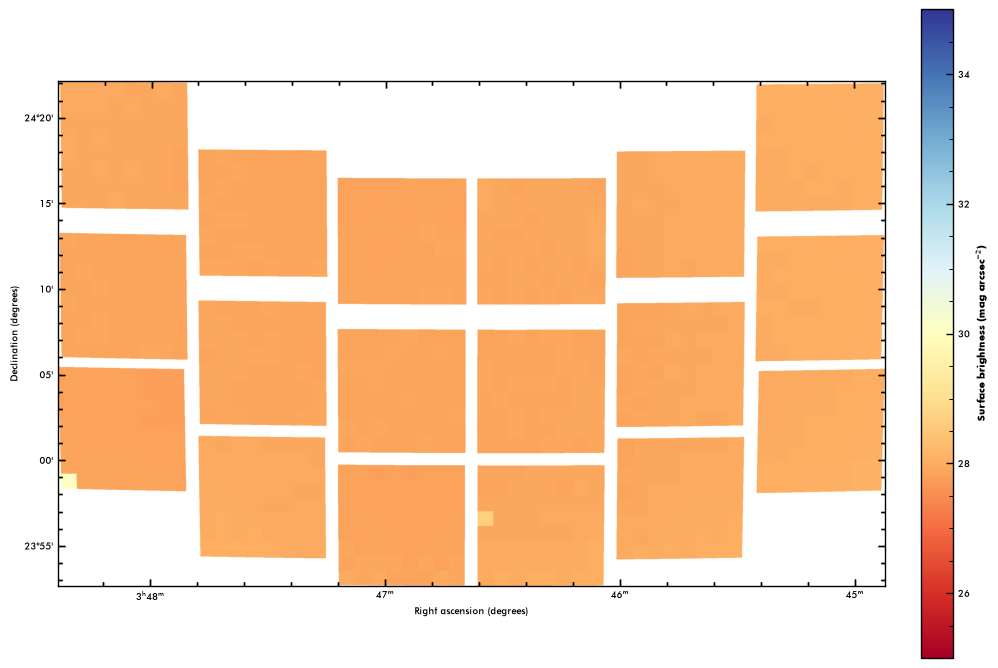

Plot: Stray-light surface brightness flux.
0.0028650782
0.00347019


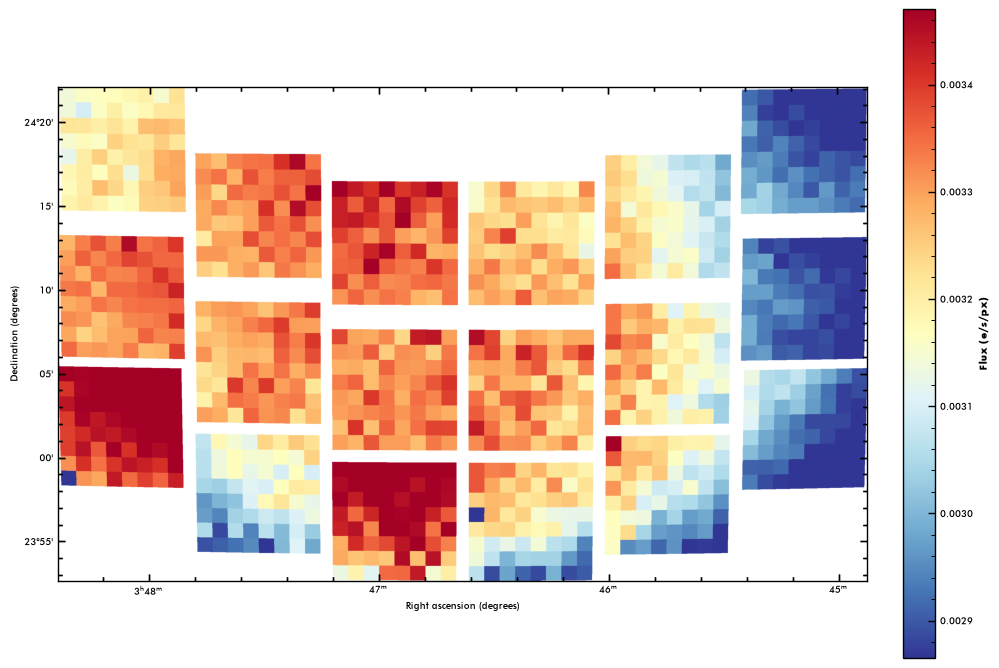

Plot: Main offender map.
11.0
158233.0
Unique IDs:
[    11     20  23325  85939 158233]
Unique IDs with counts > 1:
[    11     20  23325  85939 158233]
Simbad cannot find the name of the offender at 68.98 - 16.509762
Simbad cannot find the name of the offender at 17.43249 - 35.62083
*  17 Tau
*  16 Tau
HD  23387
Main stray-light offenders:

46.19% - (56.20, 24.29), m=6.39 - *  16 Tau
37.43% - (56.41, 24.34), m=7.65 - HD  23387
8.88% - (68.98, 16.51), m=-1.23 - CAT_ID_11
4.39% - (56.22, 24.11), m=5.02 - *  17 Tau
3.11% - (17.43, 35.62), m=-0.09 - CAT_ID_20


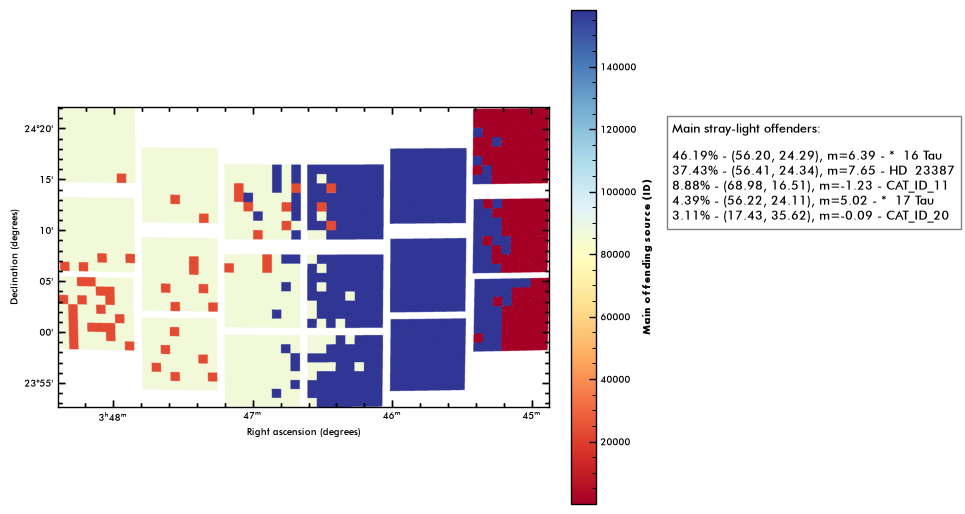

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


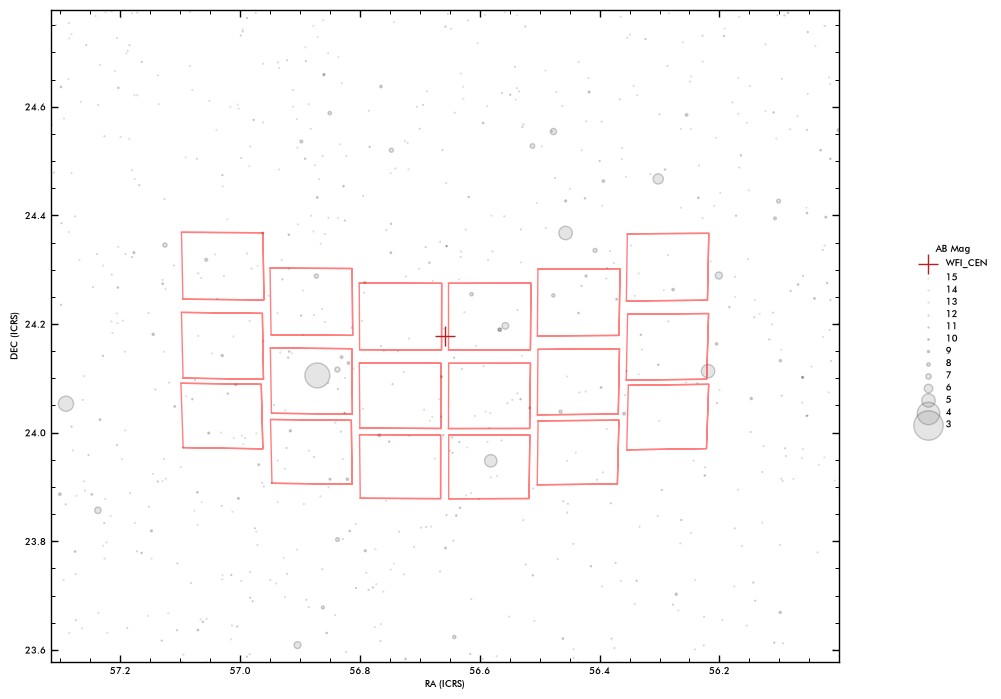

Plot: Location of Main offenders on NDI map.
Unique IDs:
[    11     20  23325  85939 158233]
Unique IDs with counts > 1:
[    11     20  23325  85939 158233]
Simbad cannot find the name of the offender at 68.98 - 16.509762
Simbad cannot find the name of the offender at 17.43249 - 35.62083
*  17 Tau
*  16 Tau
HD  23387
Main stray-light offenders:

46.19% - (56.20, 24.29), m=6.39 - *  16 Tau
37.43% - (56.41, 24.34), m=7.65 - HD  23387
8.88% - (68.98, 16.51), m=-1.23 - CAT_ID_11
4.39% - (56.22, 24.11), m=5.02 - *  17 Tau
3.11% - (17.43, 35.62), m=-0.09 - CAT_ID_20
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 56.6583333 24.1780556
CRPIX : 636.5 636.5
NAXIS : 1273  1273
2026-10-20T16:18:22.979302 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/tutorials/Pleiades_Roman_RA_056.658_DEC_024.178_MJD_61314.00000_PA_000.00_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/tutorials/Pleiades_Roman_RA_056.658_DEC_024.1

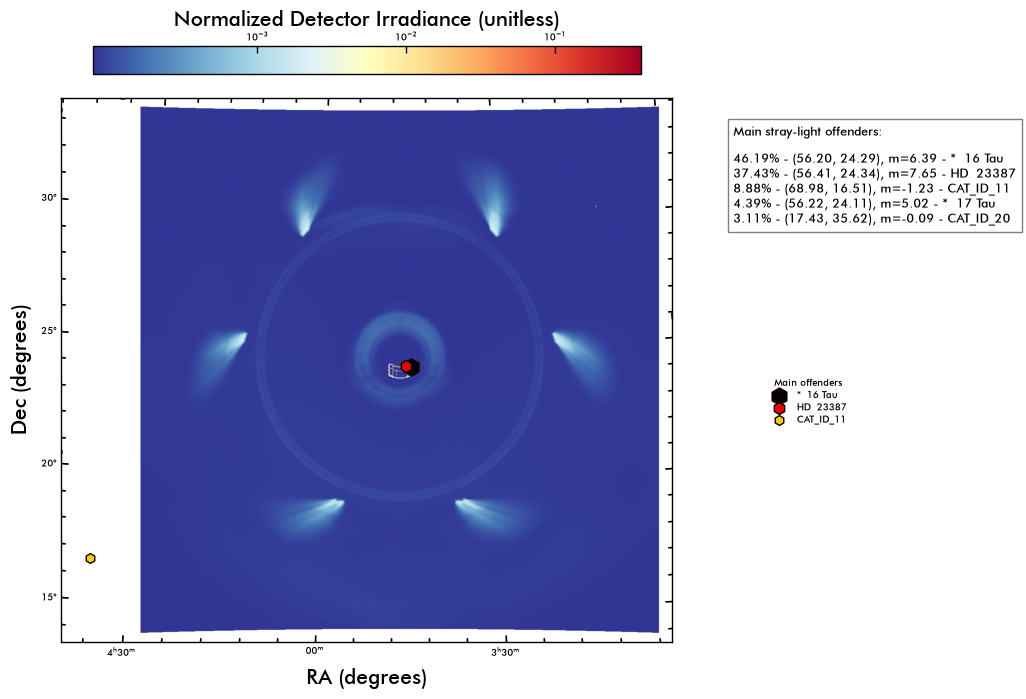

In [ ]:
# This notebook demonstrates how to use ROSALIA to analyze stray light in a simple exposure. 

# Let's define the minimum parameters to generate a dummy Roman / WFI image
# To get some challenging environment, let's target the Pleiades.
ra = 56.6583333  # Right ascension, in degrees. 
dec = +24.1780556 # Declination, in degrees.
PA = 0 # Position angle, in degrees.

date = Time("2026-10-01T00:00:00") # Date of the observation, in Astropy Time YYYY-MM-DDTHH:MM:SS format.
bandpass = "F129"
exptime = 600 # Exposure time, in seconds.


observer={"TELESCOP": "Roman/WFI", 
          "pointing": [ra, dec], 
          "FILTER":bandpass, 
          "PA_Y": PA, 
          "EXPSTART": date.mjd, 
          "EXPTIME": exptime}

prefix = "Pleiades"

# With this line we generate the exposure object. This is the first step in any ROSALIA analysis. 
custom_roman_exposure = rs.core.exposure(observer=observer, prefix=prefix) 

straylight_out = custom_roman_exposure.straylight()

### 2 - Estimating stray-light on a real observation file

In [4]:
# Here is a mock observation pre-generated by the Roman Team

# With this line we generate the exposure object. This is the first step in any ROSALIA analysis.
import glob  
input_flc = sorted(glob.glob("/Users/aborlaff/NASA/ROSALIA_DEPOT/MAST_2026-09-16T0933/MAST/Roman/r0102001002001005001_0004_wfi*_f158_cal.asdf"))
roman_exposure = rs.core.exposure(input_flc)



Retrieving exposure : 100%|██████████| 15/15 [00:04<00:00,  3.50it/s]

Currently estimated through pysiaf and quaternion. This is a temporary fix until MAST fixes the RA_TARG, DEC_TARG, PA keywords in the Roman/WFI fits files.


## About this Notebook

**Author:** Alejandro S. Borlaff - NASA Ames Research Center (Code S) - a.s.borlaff@nasa.gov 

**Updated on** September 18, 2026. 
**Last tested on** September 28, 2026. ROSALIA 1.3.2